# Figur 2 · Hvordan stemmer partierne?

**Underspørgsmål 2.** Figuren har tre dele:

- **Panel a: stemmenetværket.** Noder er politikere (MF'ere). En kant betyder, at to politikere stemmer ens markant oftere end forventet under jeres null-model. Kantvægt = *excess similarity* (observeret enighed minus forventet).
- **Panel b: communities mod partier.** Louvain finder grupper af politikere, der stemmer ens. NMI måler, hvor meget grupperne ligner partierne.
- **Panel c: partiernes stemmenetværk.** Samme opbygning som tekstnetværket i figur 1c (11 partier, hvert partis 3 stærkeste bånd), så de to kan sammenlignes direkte.

**Data:** `data/processed/milestone4c_ruleB.graphml` (jeres Rule B-netværk, samling 2025–26, 150 MF'ere med ≥ 40 afstemninger) og `data/processed/stemmer_2022_2026.csv` til panel c.

**Hvad netværket fanger:** hvem der stemmer ens ud over, hvad afstemningernes fordeling af for og imod alene ville give.
**Hvad det ikke fanger:** hvorfor de stemmer ens (partidisciplin, forlig, enighed), og stemmer fra før 2025, hvis netværket ikke bygges igen på hele perioden.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics import normalized_mutual_info_score

MAPPE = "../data/"
PARTIER = ["S", "V", "M", "SF", "DD", "LA", "KF", "EL", "DF", "RV", "ALT"]
REGERING = {"S", "V", "M"}
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2",
          "LA": "#3FB2BE", "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738",
          "SP": "#999999", "UFG": "#cccccc", "IA": "#bbbbbb", "N": "#bbbbbb", "JF": "#bbbbbb"}
SEED = 1004

## 1 · Indlæs stemmenetværket

In [7]:
G = nx.read_graphml("/Users/sabirinomar/Politics-Network/data/processed/milestone4c_ruleB.graphml")
for u, v, d in G.edges(data=True):
    d["weight"] = float(d["excess_similarity"])      # kantvægt = excess similarity

parti = {n: G.nodes[n]["party"] for n in G}
print(G.number_of_nodes(), "politikere,", G.number_of_edges(), "kanter")
print("Densitet:", round(nx.density(G), 3))
print("Komponenter:", nx.number_connected_components(G), "| isolerede:", nx.number_of_isolates(G))
pd.Series(parti).value_counts()

150 politikere, 3086 kanter
Densitet: 0.276
Komponenter: 6 | isolerede: 3


S      44
V      18
DD     15
LA     14
SF     12
KF     10
M       9
EL      8
DF      5
RV      5
ALT     5
UFG     4
SP      1
Name: count, dtype: int64

## 2 · Find communities med Louvain

Louvain er tilfældig, så vi kører den med 20 seeds og tjekker, at resultatet er stabilt (NMI mellem kørslerne). Vi bruger seed 1004 som den repræsentative løsning, ligesom jeres milestone 5A.

In [8]:
koersler = {s: nx.community.louvain_communities(G, weight="weight", seed=s) for s in range(1001, 1021)}


def labels(comms):
    lab = {n: i for i, c in enumerate(comms) for n in c}
    return [lab[n] for n in G]


L = {s: labels(c) for s, c in koersler.items()}
stabilitet = [normalized_mutual_info_score(L[a], L[b]) for a in L for b in L if a < b]
print(f"Stabilitet over 20 seeds: gennemsnitlig NMI = {np.mean(stabilitet):.3f}")

comms = koersler[SEED]
Q = nx.community.modularity(G, comms, weight="weight")
nmi_parti = normalized_mutual_info_score([parti[n] for n in G], labels(comms))
print(f"{len(comms)} communities, modularity Q = {Q:.3f}, NMI(parti, community) = {nmi_parti:.3f}")

Stabilitet over 20 seeds: gennemsnitlig NMI = 0.962
9 communities, modularity Q = 0.153, NMI(parti, community) = 0.645


## 3 · Er strukturen stærkere end tilfældigt? (null-model)

Vi blander kanterne med degree-preserving edge swaps (uge 2), så hver politiker beholder sin grad. Netværket er tæt (densitet 0,28), så mange swaps bliver afvist; 3 swaps pr. kant er nok til at blande det. Vi blander også vægtene tilfældigt på de nye kanter. Derefter kører vi Louvain igen og beregner Q. Med `N_NULL = 100` tager det et par minutter.

In [9]:
N_NULL = 100
rng = np.random.default_rng(1)
vaegte = np.array([d["weight"] for _, _, d in G.edges(data=True)])

Q_null = []
for i in range(N_NULL):
    H = nx.Graph(G)
    nx.double_edge_swap(H, nswap=3 * H.number_of_edges(), max_tries=1000 * H.number_of_edges(), seed=int(rng.integers(1e9)))
    for (u, v), w in zip(H.edges(), rng.permutation(vaegte)):
        H[u][v]["weight"] = w
    Q_null.append(nx.community.modularity(H, nx.community.louvain_communities(H, weight="weight", seed=SEED), weight="weight"))
Q_null = np.array(Q_null)
p_Q = (1 + (Q_null >= Q).sum()) / (1 + N_NULL)
print(f"Q = {Q:.3f}  mod null {Q_null.mean():.3f} ± {Q_null.std():.3f},  p = {p_Q:.4f}")

Q = 0.153  mod null 0.063 ± 0.002,  p = 0.0099


## 4 · Panel a: stemmenetværket

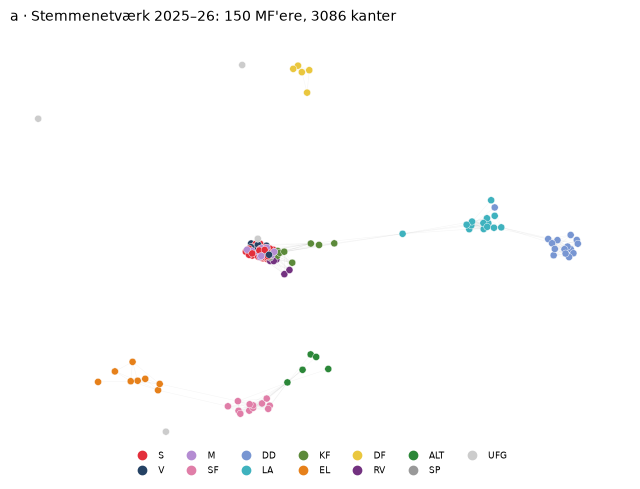

In [10]:
def tegn_panel_a(ax):
    pos = nx.spring_layout(G, weight="weight", seed=5, k=0.25, iterations=200)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.04, width=0.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=26, linewidths=0.3, edgecolors="white",
                           node_color=[FARVER.get(parti[n], "#ccc") for n in G])
    til_stede = [p for p in PARTIER + ["SP", "UFG"] if p in set(parti.values())]
    ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=FARVER[p], label=p) for p in til_stede],
              ncol=7, fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.02))
    ax.set_title(f"a · Stemmenetværk 2025–26: {G.number_of_nodes()} MF'ere, {G.number_of_edges()} kanter",
                 fontsize=10, loc="left")
    ax.axis("off")


fig, ax = plt.subplots(figsize=(6.5, 5)); tegn_panel_a(ax); plt.tight_layout(); plt.show()

## 5 · Panel b: hvilke partier ligger i hvilke communities?

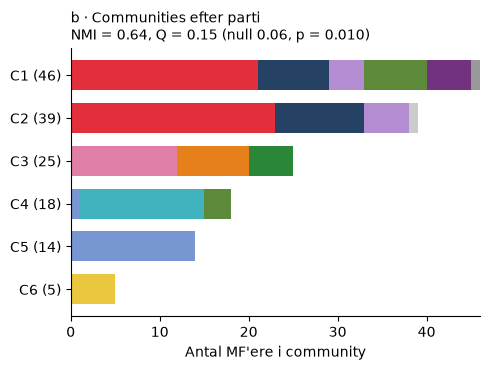

,S,V,M,SF,DD,LA,KF,EL,DF,RV,ALT,SP,UFG
C1 (46),21,8,4,0,0,0,7,0,0,5,0,1,0
C2 (39),23,10,5,0,0,0,0,0,0,0,0,0,1
C3 (25),0,0,0,12,0,0,0,8,0,0,5,0,0
C4 (18),0,0,0,0,1,14,3,0,0,0,0,0,0
C5 (14),0,0,0,0,14,0,0,0,0,0,0,0,0
C6 (5),0,0,0,0,0,0,0,0,5,0,0,0,0


In [11]:
def tegn_panel_b(ax):
    store = [c for c in sorted(comms, key=len, reverse=True) if len(c) > 1]
    til_stede = [p for p in PARTIER + ["SP", "UFG"] if p in set(parti.values())]
    mat = pd.DataFrame([[sum(parti[n] == p for n in c) for p in til_stede] for c in store],
                       columns=til_stede, index=[f"C{i+1} ({len(c)})" for i, c in enumerate(store)])
    venstre = np.zeros(len(mat))
    for p in til_stede:
        ax.barh(range(len(mat)), mat[p].values, left=venstre, color=FARVER[p], height=0.7)
        venstre += mat[p].values
    ax.set_yticks(range(len(mat)), mat.index); ax.invert_yaxis()
    ax.set_xlabel("Antal MF'ere i community")
    ax.set_title(f"b · Communities efter parti\nNMI = {nmi_parti:.2f}, Q = {Q:.2f} (null {Q_null.mean():.2f}, p = {p_Q:.3f})",
                 fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    return mat


fig, ax = plt.subplots(figsize=(5, 3.8)); mat = tegn_panel_b(ax); plt.tight_layout(); plt.show()
mat

## 6 · Panel c: partiernes stemmenetværk

Her bliver noderne partier, så netværket kan sammenlignes med tekstnetværket i figur 1c.

1. **Partiets position** på en afstemning er flertallet blandt de medlemmer, der stemte (For, Imod eller Hverken). Fravær tæller ikke.
2. **Kantvægt** er andelen af fælles afstemninger, hvor de to partier havde samme position.
3. **Backbone:** hvert partis 3 stærkeste bånd, præcis som i figur 1c.

In [13]:
st = pd.read_csv("/Users/sabirinomar/Politics-Network/data/processed/stemmer_2022_2026.csv", usecols=["afstemning_id", "parti", "stemme"])
st = st[st["parti"].isin(PARTIER) & st["stemme"].isin(["For", "Imod", "Hverken for eller imod"])]
position = (st.groupby(["afstemning_id", "parti"])["stemme"]
              .agg(lambda x: x.value_counts().idxmax()).unstack()[PARTIER])
print(len(position), "afstemninger")


def enighed(a, b):
    faelles = position[a].notna() & position[b].notna()
    return (position.loc[faelles, a] == position.loc[faelles, b]).mean()


E = np.array([[enighed(a, b) if a != b else np.nan for b in PARTIER] for a in PARTIER])
enig = pd.DataFrame(E, index=PARTIER, columns=PARTIER)

par = enig.where(np.triu(np.ones(enig.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(par.head(8).round(3))

1514 afstemninger
S   M      0.999
    V      0.993
V   M      0.992
EL  ALT    0.843
SF  RV     0.820
    EL     0.816
M   RV     0.800
S   RV     0.800
dtype: float64


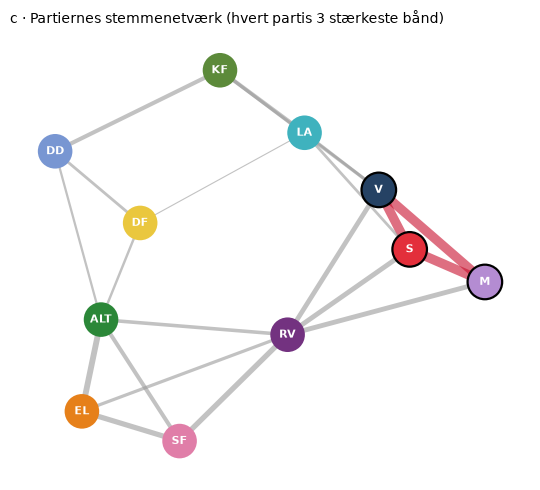

In [ ]:
def partinetvaerk(M, k=3):
    H = nx.Graph(); H.add_nodes_from(M.index)
    for p in M.index:
        for q, w in M.loc[p].drop(p).nlargest(k).items():
            H.add_edge(p, q, weight=float(w))
    return H


def tegn_panel_c(ax, k=3):
    H = partinetvaerk(enig, k)
    pos = nx.spring_layout(H, weight="weight", seed=4)
    w = np.array([H[u][v]["weight"] for u, v in H.edges()])
    nx.draw_networkx_edges(H, pos, ax=ax, width=0.8 + 6 * (w - w.min()) / (w.max() - w.min() + 1e-9), alpha=0.6,
                           edge_color=["#c8102e" if u in REGERING and v in REGERING else "#9a9a9a" for u, v in H.edges()])
    nx.draw_networkx_nodes(H, pos, ax=ax, node_color=[FARVER[p] for p in H], node_size=620,
                           edgecolors=["k" if p in REGERING else "none" for p in H], linewidths=1.6)
    nx.draw_networkx_labels(H, pos, ax=ax, font_size=8, font_color="white", font_weight="bold")
    ax.set_title(f"c · Partiernes stemmenetværk (hvert partis {k} stærkeste bånd)", fontsize=10, loc="left")
    ax.axis("off")
    return H


fig, ax = plt.subplots(figsize=(5.5, 5)); Hc = tegn_panel_c(ax); plt.tight_layout(); plt.show()

## 7b · Ekstra: for og imod pr. emne (simpelt søjlediagram)

For hvert emne: hvor stor en andel af lovforslagene (endelige vedtagelser) stemte partiet *for*? Partiets stemme er flertallet blandt de medlemmer, der stemte. Sort kant = regeringsparti.

**Pas på i fortolkningen:** en for-stemme om et klimalovforslag er ikke nødvendigvis en stemme *for* mere klima, fordi en lov kan gå begge veje. Figuren viser altså, hvor ofte partiet bakker op om lovgivningen på området, ikke hvad det mener. Til alignment skal I bruge nøglelovene med retning (figur 5).

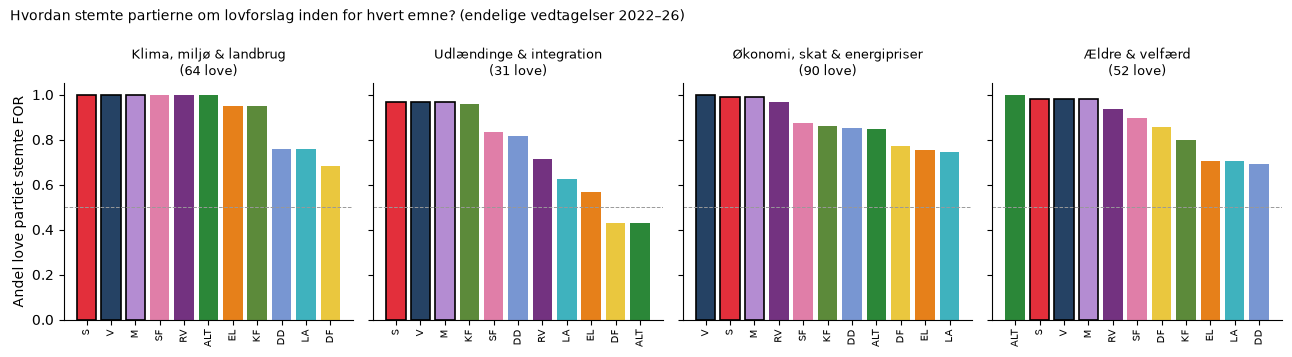

emne,"Klima, miljø & landbrug",Udlændinge & integration,Ældre & velfærd,"Økonomi, skat & energipriser"
parti,,,,
S,1.00,0.97,0.98,0.99
V,1.00,0.97,0.98,1.00
M,1.00,0.97,0.98,0.99
SF,1.00,0.83,0.90,0.88
DD,0.76,0.81,0.69,0.85
LA,0.76,0.62,0.70,0.74
KF,0.95,0.96,0.80,0.86
EL,0.95,0.57,0.71,0.75
DF,0.68,0.43,0.86,0.77


In [ ]:
st = pd.read_csv(MAPPE + "processed/stemmer_2022_2026.csv",
                 usecols=["afstemning_id", "afstemningstype", "sagstype", "emne", "parti", "stemme"])
st = st[st["parti"].isin(PARTIER) & (st["afstemningstype"] == "Endelig vedtagelse")
        & (st["sagstype"] == "Lovforslag") & st["stemme"].isin(["For", "Imod"])]

# partiets position pr. lov = flertallet af dets medlemmer
pos = (st.groupby(["afstemning_id", "emne", "parti"])["stemme"]
         .agg(lambda x: x.value_counts().idxmax()).reset_index())
pos["for"] = (pos["stemme"] == "For").astype(int)

EMNER = ["Klima, miljø & landbrug", "Udlændinge & integration", "Økonomi, skat & energipriser", "Ældre & velfærd"]
andel = pos[pos["emne"].isin(EMNER)].pivot_table(index="parti", columns="emne", values="for", aggfunc="mean").reindex(PARTIER)
antal = pos[pos["emne"].isin(EMNER)].groupby("emne")["afstemning_id"].nunique()

fig, axes = plt.subplots(1, len(EMNER), figsize=(13, 3.6), sharey=True)
for ax, emne in zip(axes, EMNER):
    v = andel[emne].sort_values(ascending=False)
    ax.bar(v.index, v.values, color=[FARVER[p] for p in v.index],
           edgecolor=["k" if p in REGERING else "none" for p in v.index], linewidth=1.2)
    ax.axhline(0.5, color="#999", lw=0.7, ls="--")
    ax.set_title(f"{emne}\n({antal[emne]} love)", fontsize=9)
    ax.tick_params(axis="x", labelsize=7, rotation=90)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Andel love partiet stemte FOR")
axes[0].set_ylim(0, 1.05)
fig.suptitle("Hvordan stemte partierne om lovforslag inden for hvert emne? (endelige vedtagelser 2022–26)", fontsize=10, x=0.01, ha="left")
plt.tight_layout()
fig.savefig("fig2d_for_imod_pr_emne.png", dpi=200, bbox_inches="tight")
plt.show()
andel.round(2)

## 7 · Saml figur 2 til paperet

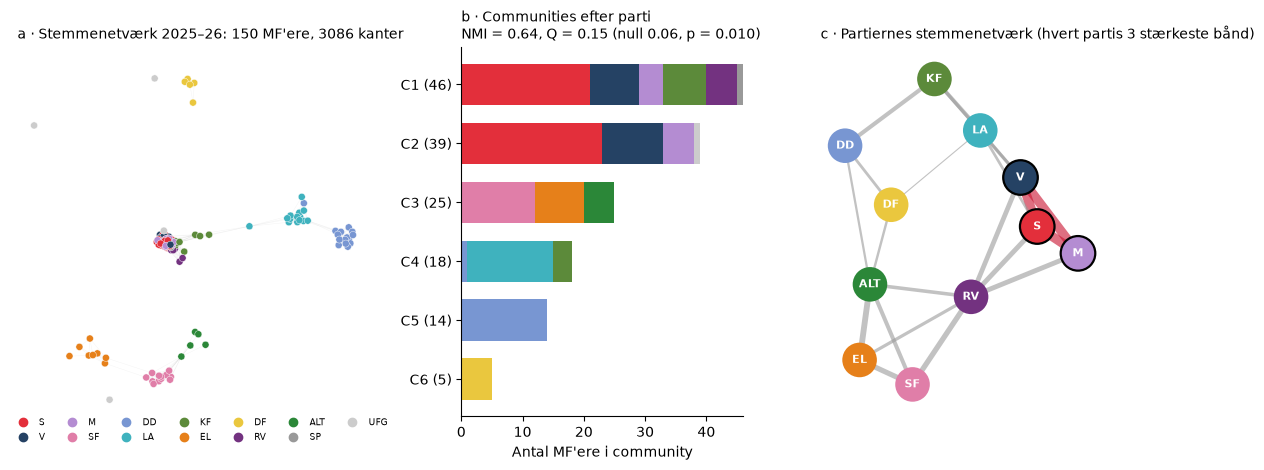

In [ ]:
fig = plt.figure(figsize=(14, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1, 1], wspace=0.25)
tegn_panel_a(fig.add_subplot(gs[0]))
tegn_panel_b(fig.add_subplot(gs[1]))
tegn_panel_c(fig.add_subplot(gs[2]))
fig.savefig("fig2_hvordan_stemmer_de.pdf", bbox_inches="tight")
fig.savefig("fig2_hvordan_stemmer_de.png", dpi=300, bbox_inches="tight")
plt.show()

på figur a, Hver prik er en politiker, og en streg betyder, at to politikere stemmer ens oftere, end man ville forvente. Prikker med mange stærke streger imellem sig trækkes sammen i tegningen. At S, V og M ligger oven i hinanden betyder, at deres politikere stort set stemmer som én blok. SF, EL og ALT danner en anden blok, og DF ligger for sig selv, fordi DF sjældent stemmer som de andre.

På figur B, har vi en null model - hvor vi kigger ind i om grupperingen er stærkere end tilfældigt?
For at tjekke, om Folketinget reelt er delt op i politiske blokke, laver man en null-model (typisk en configuration model):

Man beholder politikernes "aktivitet": Hvis Mette Frederiksen har 45 forbindelser i netværket, og en løsgænger kun har 2, beholder de præcis det antal forbindelser.

En "blindtest", hvor en computer inddeler politikerne i 6 naturlige kliker (C1–C6) uden at kende deres parti. Tallene i toppen beviser mod en tilfældighedsmodel (null-model), at opdelingen er reel og ikke bare støj.


På figur C 

In [ ]:
## 6b · Centralitet i partinetværket (Hc) og MF-netværket (G)

# 1. Betweenness på partiniveau (Hc) - husk at vende vægten om til "afstand" (1 - enighed),
# fordi korteste vej i networkx tolker weight som pris/afstand, ikke styrke!
for u, v, d in Hc.edges(data=True):
    d["distance"] = 1.0 - d["weight"]

bc_parti = nx.betweenness_centrality(Hc, weight="distance", normalized=True)
deg_parti = dict(Hc.degree())

df_cent = pd.DataFrame({
    "Degree (antal bånd i backbone)": pd.Series(deg_parti),
    "Betweenness (brobygger)": pd.Series(bc_parti).round(3)
}).sort_values("Betweenness (brobygger)", ascending=False)

print("Centralitet i partiernes backbone-netværk (Hc):")
display(df_cent)

# 2. Gennemsnitlig betweenness pr. parti i selve MF-netværket (G)
for u, v, d in G.edges(data=True):
    d["distance"] = 1.0 / (d["weight"] + 1e-6) # høj excess similarity = kort afstand

bc_mf = nx.betweenness_centrality(G, weight="distance", normalized=True)
df_mf_cent = pd.DataFrame({
    "parti": [parti[n] for n in G],
    "betweenness": [bc_mf[n] for n in G]
})
print("\nGennemsnitlig betweenness pr. MF'er fordelt på parti (G):")
display(df_mf_cent.groupby("parti")["betweenness"].mean().sort_values(ascending=False).round(4))

Centralitet i partiernes backbone-netværk (Hc):


,Degree (antal bånd i backbone),Betweenness (brobygger)
V,5,0.289
RV,6,0.267
ALT,5,0.156
S,4,0.111
KF,3,0.089
DD,3,0.067
LA,4,0.067
DF,3,0.022
M,3,0.000
SF,3,0.000



Gennemsnitlig betweenness pr. MF'er fordelt på parti (G):


parti
LA     0.0393
KF     0.0247
DD     0.0077
RV     0.0023
S      0.0017
EL     0.0017
SP     0.0015
ALT    0.0015
SF     0.0014
V      0.0011
M      0.0007
DF     0.0000
UFG    0.0000
Name: betweenness, dtype: float64

En centralitetsanalyse understøtter og nuancerer billedet af brobyggere i Folketinget. I partiernes backbone-netværk for hele perioden (panel c) har Venstre (betweenness = 0,289) og Radikale Venstre (0,267) den højeste mellemcentralitet: V binder regeringen sammen med højrefløjen, mens RV (med 6 forbindelser i alt) binder regeringen sammen med venstrefløjen. Ser man derimod på det signifikante stemmenetværk på MF-niveau i 2025–26 (panel a), er det enkelte medlemmer fra LA (0,039) og KF (0,025), der har den højeste gennemsnitlige betweenness, fordi de fysisk danner bindeleddet mellem SVM-kernen og Danmarksdemokraterne – mens DF (0,000) står helt uden for brobygningen.

## 8 · Til captionen

Udfyld tallene i [klammer]:

*How the parties vote. (a) Voting network of the 2025–26 session: nodes are MPs with ≥ 40 votes (n = 150); edges connect MPs who agree significantly more often than expected under a vote-preserving null (excess similarity > 0, BH-adjusted q < 0.05); colour = party. (b) Louvain communities (seed 1004) by party composition. Communities overlap with parties (NMI = [0.64]) but group them into blocs; modularity Q = [0.15] versus [0.06] in [100] degree-preserving rewirings (p = [0.01]). (c) Party-level voting network, 2022–26: each party is linked to the three parties it most often votes with; S, V and M form the tightest triangle.*